In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [6]:
df = pd.read_csv("00_df_feat_ADV_19_V01.csv")

In [7]:
#df.head()
#df.tail()

In [8]:
# df.info()
df_cleaned = df.replace(["", " ", "None", "null", "-"], np.nan)
print(df_cleaned.isna().sum())

f_volume_core_estimated_nm3    0
f_area_core_estimated_nm2      0
f_area_volume_ratio            0
f_ratio_Zn_Fe                  0
f_ratio_Co_Fe                  0
f_ratio_Mn_Fe                  0
f_ratio_Mg_Fe                  0
f_conc_MNP_mg_mL               0
f_avg_core_width_nm_BOTH       0
f_avg_core_sd_nm_BOTH          0
f_SAR_W_g_MNP_core_BOTH        0
f_H_Oe_BOTH                    0
f_FCY_kHz_BOTH                 0
f_Ms_emu_g_MNP_BOTH            0
f_Mr_emu_g_MNP_BOTH            0
f_Mr_Ms_BOTH                   0
f_Hc_Oe_BOTH                   0
f_Tem_mp_K_BOTH                0
c_is_coated                    0
c_is_inorganic                 0
c_is_water_soluble             0
c_is_oil_soluble               0
c_is_composite_coating         0
c_is_non_aqueous_medium        0
c_is_fluid_medium              0
c_contains_stabilizer          0
c_is_cubic                     0
c_is_nanoflower                0
c_is_octahedron                0
c_is_octopod                   0
c_is_spher

In [9]:
df.columns
#print(df['c_is_coated'])

Index(['f_volume_core_estimated_nm3', 'f_area_core_estimated_nm2',
       'f_area_volume_ratio', 'f_ratio_Zn_Fe', 'f_ratio_Co_Fe',
       'f_ratio_Mn_Fe', 'f_ratio_Mg_Fe', 'f_conc_MNP_mg_mL',
       'f_avg_core_width_nm_BOTH', 'f_avg_core_sd_nm_BOTH',
       'f_SAR_W_g_MNP_core_BOTH', 'f_H_Oe_BOTH', 'f_FCY_kHz_BOTH',
       'f_Ms_emu_g_MNP_BOTH', 'f_Mr_emu_g_MNP_BOTH', 'f_Mr_Ms_BOTH',
       'f_Hc_Oe_BOTH', 'f_Tem_mp_K_BOTH', 'c_is_coated', 'c_is_inorganic',
       'c_is_water_soluble', 'c_is_oil_soluble', 'c_is_composite_coating',
       'c_is_non_aqueous_medium', 'c_is_fluid_medium', 'c_contains_stabilizer',
       'c_is_cubic', 'c_is_nanoflower', 'c_is_octahedron', 'c_is_octopod',
       'c_is_spherical'],
      dtype='object')

In [10]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

columns_to_scale = [
    'f_volume_core_estimated_nm3', 'f_area_core_estimated_nm2', 'f_area_volume_ratio',
    'f_ratio_Zn_Fe', 'f_ratio_Co_Fe', 'f_ratio_Mn_Fe', 'f_ratio_Mg_Fe',
    'f_conc_MNP_mg_mL', 'f_avg_core_width_nm_BOTH'
    ]

df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])
print(df)


      f_volume_core_estimated_nm3  f_area_core_estimated_nm2  \
0                        0.030372                   0.117430   
1                        0.054175                   0.173973   
2                        0.123169                   0.302928   
3                        0.030372                   0.117430   
4                        0.054175                   0.173973   
...                           ...                        ...   
1845                     0.017537                   0.051418   
1846                     0.017537                   0.051418   
1847                     0.017537                   0.051418   
1848                     0.017537                   0.051418   
1849                     0.017537                   0.051418   

      f_area_volume_ratio  f_ratio_Zn_Fe  f_ratio_Co_Fe  f_ratio_Mn_Fe  \
0                0.276575            0.0            0.0            0.0   
1                0.212308            0.0            0.0            0.0   
2        

#Data set one

#Ridge Regrassion

In [11]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

#-------------Physical properties---------------------------------------
feature_columns = columns_to_scale +['c_is_coated', 'c_is_inorganic',
    'c_is_water_soluble', 'c_is_oil_soluble', 'c_is_composite_coating',
    'c_is_non_aqueous_medium', 'c_is_fluid_medium', 'c_contains_stabilizer',
    'c_is_cubic', 'c_is_nanoflower', 'c_is_octahedron', 'c_is_octopod',
    'c_is_spherical', 'f_H_Oe_BOTH', 'f_FCY_kHz_BOTH', 'f_Ms_emu_g_MNP_BOTH',
    'f_Mr_emu_g_MNP_BOTH', 'f_Mr_Ms_BOTH', 'f_Hc_Oe_BOTH', 'f_Tem_mp_K_BOTH']

X = df[feature_columns]
y = df['f_SAR_W_g_MNP_core_BOTH']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

y_pred = ridge_model.predict(X_test)

print(f"R² value from Physical properties using R.Regrassion model: {r2_score(y_test, y_pred):.2f}")
print(f"MSE value from Physical properties using R.Regression model: {mean_squared_error(y_test, y_pred):.2f}")
#-----------------------------------------Magnetic properties----------

#X1 = df[['f_H_Oe_BOTH', 'f_FCY_kHz_BOTH', 'f_Ms_emu_g_MNP_BOTH', 'f_Mr_emu_g_MNP_BOTH', 'f_Mr_Ms_BOTH', 'f_Hc_Oe_BOTH', 'f_Tem_mp_K_BOTH']]
#y1 = df['f_SAR_W_g_MNP_core_BOTH']

#X1_train, X1_test, y1_train, y1_test = train_test_split(
#    X1, y1,
#    test_size=0.2,
#   random_state=42
#)

#ridge_model = Ridge(alpha=1.0)
#ridge_model.fit(X1_train, y1_train)

#y1_pred = ridge_model.predict(X1_test)

#print(f"R² value from Magnetic properties using R.Regrassion model: {r2_score(y1_test, y1_pred):.2f}")
#print(f"MSE value from Magnetic properties using R.Regression model: {mean_squared_error(y1_test, y1_pred):.2f}")

R² value from Physical properties using R.Regrassion model: 0.60
MSE value from Physical properties using R.Regression model: 38170.83


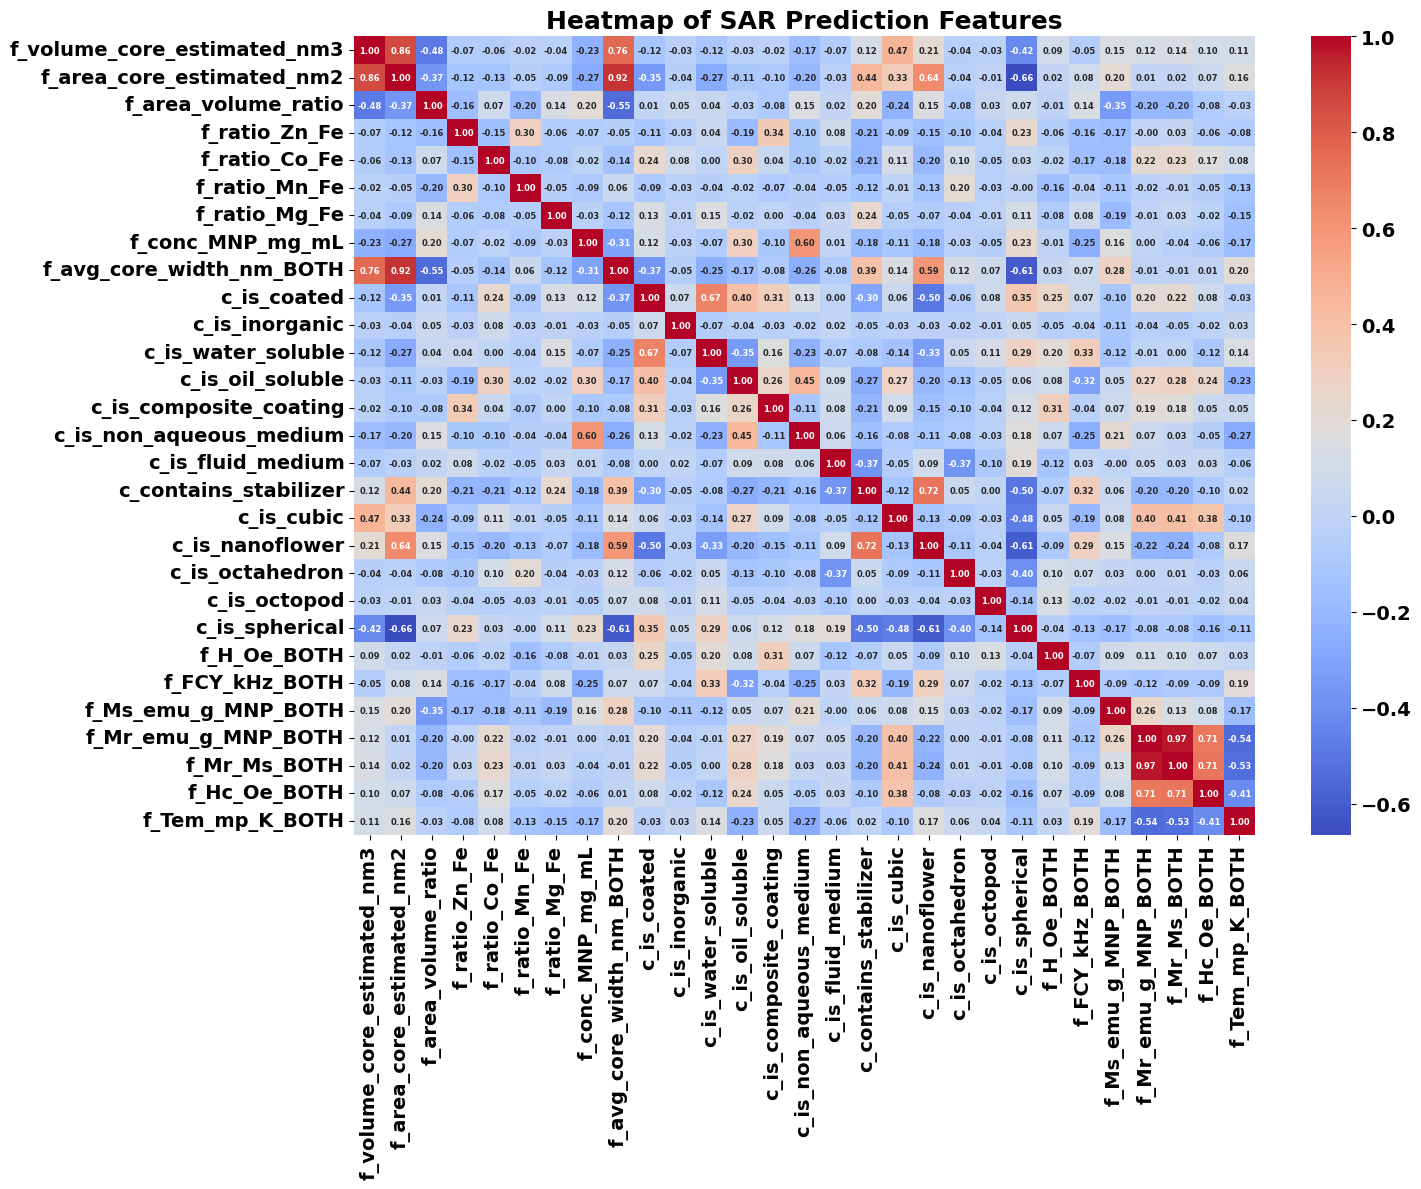

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
import seaborn as sns

numeric_df = df[feature_columns].select_dtypes(include=['number'])
plt.figure(figsize=(15, 12))
correlation_matrix = numeric_df.corr()

ax = sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6, 'weight': 'bold'}
)

plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')

cbar = ax.collections[0].colorbar
plt.setp(cbar.ax.get_yticklabels(), fontweight='bold', fontsize=14)

plt.title('Heatmap of SAR Prediction Features', fontweight='bold', fontsize=18)
plt.tight_layout()
plt.savefig('SAR_feature_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
from google.colab import files
files.download('SAR_feature_heatmap.png')

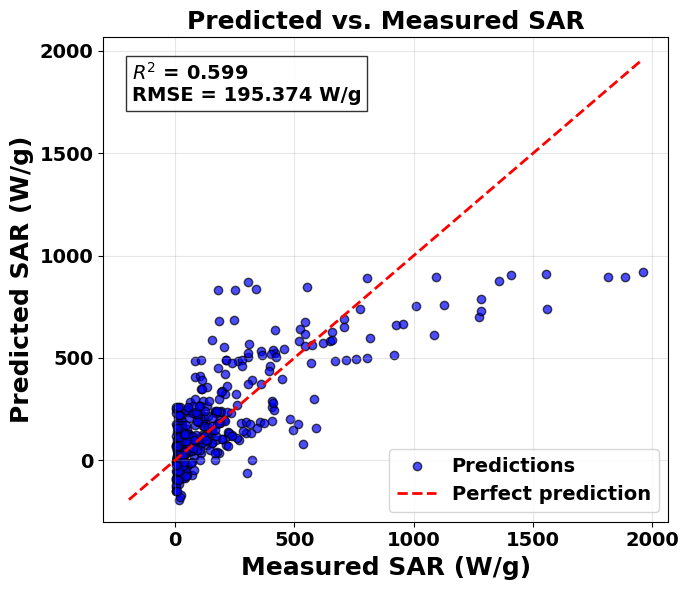

In [17]:

y_measured = y_test
y_predicted = y_pred


r2 = r2_score(y_measured, y_predicted)
rmse = np.sqrt(mean_squared_error(y_measured, y_predicted))


plt.figure(figsize=(7, 6))

plt.scatter(
    y_measured,
    y_predicted,
    color="blue",
    alpha=0.7,
    edgecolors="black",
    label="Predictions"
)


min_val = min(np.min(y_measured), np.min(y_predicted))
max_val = max(np.max(y_measured), np.max(y_predicted))

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')
plt.xlabel("Measured SAR (W/g)", fontweight='bold', fontsize=18)
plt.ylabel("Predicted SAR (W/g)", fontweight='bold', fontsize=18)
plt.title("Predicted vs. Measured SAR", fontweight='bold', fontsize=18)
plt.text(
    0.05, 0.95,
    f"$R^2$ = {r2:.3f}\nRMSE = {rmse:.3f} W/g",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    fontdict={'fontsize': 14, 'weight': 'bold'},
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend(prop={'size': 14, 'weight': 'bold'})
plt.grid(True, alpha=0.3)
plt.tight_layout()

#plt.tight_layout()
plt.savefig('Ridge_SAR.png', dpi=300, bbox_inches='tight')
#plt.show()

plt.show()

In [37]:
#plt.tight_layout()
#plt.savefig('Ridge_SAR.png', dpi=300, bbox_inches='tight')
#plt.show()


from google.colab import files
files.download('Ridge_SAR.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Random Forest

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

#-------------Physical properties---------------------------------------
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred2 = rf_model.predict(X_test)

print(f"R² value from Physical properties using R.Forest model: {r2_score(y_test, y_pred2):.4f}")
print(f"MSE value from Physical properties using R.Forest model: {mean_squared_error(y_test, y_pred2):.4f}")




#-----------------------------------------Magnetic properties----------
#rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
#rf_model.fit(X1_train, y1_train)
#y1_pred2 = rf_model.predict(X1_test)

#print(f"R² value from magnetic properties using R.Forest model: {r2_score(y1_test, y1_pred2):.2f}")
#print(f"MSE value from Magnetic properties using R.Forest model: {mean_squared_error(y1_test, y1_pred2):.2f}")

R² value from Physical properties using R.Forest model: 0.9753
MSE value from Physical properties using R.Forest model: 2349.0271


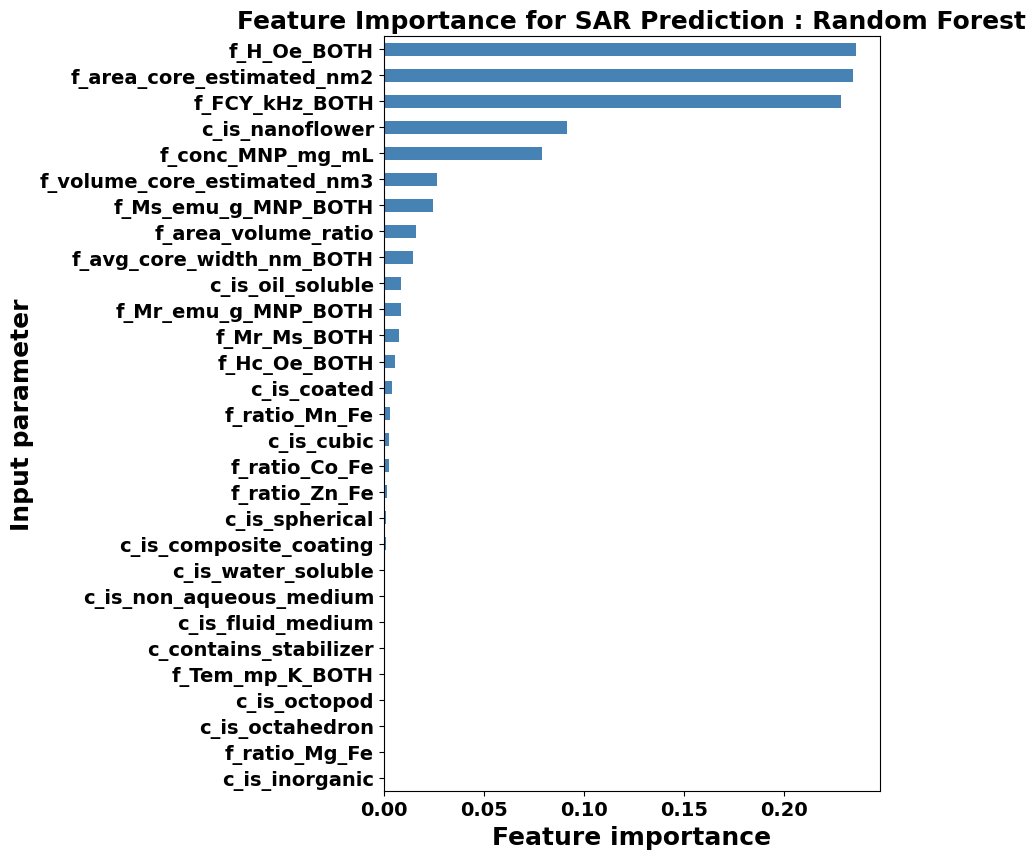

In [29]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, max(6, len(importance) * 0.3)))
importance.plot(kind='barh', color='steelblue')

plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')

plt.xlabel('Feature importance', fontweight='bold', fontsize=18)
plt.ylabel('Input parameter', fontweight='bold', fontsize=18)
plt.title('Feature Importance for SAR Prediction : Random Forest', fontweight='bold', fontsize=18)
plt.tight_layout()

plt.savefig('Feature Importance for SAR Prediction.png', dpi=300, bbox_inches='tight')
plt.show()

In [30]:
#plt.tight_layout()
#plt.savefig('Ridge_SAR.png', dpi=300, bbox_inches='tight')
#plt.show()


from google.colab import files
files.download('Feature Importance for SAR Prediction.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

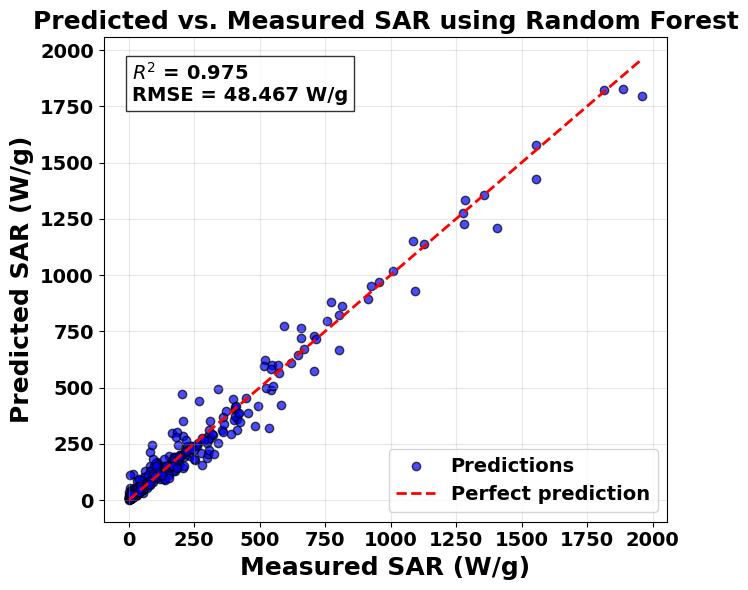

In [34]:

y_measured = y_test
y_predicted2 = y_pred2


r2 = r2_score(y_measured, y_predicted2)
rmse = np.sqrt(mean_squared_error(y_measured, y_predicted2))


plt.figure(figsize=(7, 6))

plt.scatter(
    y_measured,
    y_predicted2,
    color="blue",
    alpha=0.7,
    edgecolors="black",
    label="Predictions"
)


min_val = min(np.min(y_measured), np.min(y_predicted2))
max_val = max(np.max(y_measured), np.max(y_predicted2))

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')

plt.xlabel("Measured SAR (W/g)", fontweight='bold', fontsize=18)
plt.ylabel("Predicted SAR (W/g)", fontweight='bold', fontsize=18)
plt.title("Predicted vs. Measured SAR using Random Forest", fontweight='bold', fontsize=18)
plt.text(
    0.05, 0.95,
    f"$R^2$ = {r2:.3f}\nRMSE = {rmse:.3f} W/g",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    fontdict={'fontsize': 14, 'weight': 'bold'},
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.legend(prop={'size': 14, 'weight': 'bold'})
plt.grid(True, alpha=0.3)
plt.tight_layout()

#plt.tight_layout()
plt.savefig('RF_SAR.png', dpi=300, bbox_inches='tight')
#plt.show()


#from google.colab import files
#files.download('RF_SAR.png')

plt.show()

In [36]:
#plt.tight_layout()
#plt.savefig('RF_SAR.png', dpi=300, bbox_inches='tight')
#plt.show()


from google.colab import files
files.download('RF_SAR.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#The R.Forest model using magnetic properties looks better!
#The R.Regration model using magnetic properties fails!

#SVM

In [ ]:
from sklearn.svm import SVC
from sklearn.svm import SVR

svm_regressor = SVR(kernel='rbf', C=1.0) #non-linear kernel
svm_regressor.fit(X_train, y_train)
y_pred_l = svm_regressor.predict(X_test)

print(f"SVR R² value: {r2_score(y_test, y_pred_l):.2f}")
print(f"SVR MSE: {mean_squared_error(y_test, y_pred_l):.2f}")
print(f"Number of support vectors: {svm_regressor.n_support_}")

SVR R² value: -0.16
SVR MSE: 110298.97
Number of support vectors: [1480]


#SVM fails!

#data set 2

In [ ]:
df2 = pd.read_csv("dataset3_iron_oxide_nanoflowers_tables_text_sup_errors_separate.csv")

In [ ]:
df2.columns


Index(['Sample', 't1_d_TEM_nm', 't1_d_TEM_nm_error', 't1_d_core_nm',
       't1_d_core_nm_error', 't1_N_core_mean', 't1_d_XRD_nm',
       't1_d_XRD_nm_error', 't1_a_Angstrom', 't1_a_Angstrom_error',
       't1_D_z_nm', 't1_PDI_unitless', 't1_D1_nm',
       't1_D2_nm_and_weight_percent', 't2_d_w_nm', 't2_d_n_nm',
       't2_chi_unitless', 't2_Ms_kA_m', 't2_TB_mean_K', 't2_Keff_1e4_J_m3',
       't2_DeltaEani_1e_minus20_J', 't2_HK_kA_m', 't3_A_H24_mJ_kg',
       't3_A_H24_mJ_kg_error', 't3_SAR_H24_W_g_Fe2O3',
       't3_SAR_H24_W_g_Fe2O3_error', 't3_A_H12_mJ_kg', 't3_A_H12_mJ_kg_error',
       't3_SAR_H12_W_g_Fe2O3', 't3_SAR_H12_W_g_Fe2O3_error',
       'text_sample_synthesis_and_interpretation', 'text_dTEM_sample_nm',
       'text_dTEM_overall_range_nm', 'text_optimal_dTEM_at_Hmax12_nm',
       'text_sample_with_optimal_SAR_at_Hmax12',
       'text_max_SAR_at_280kHz_Hmax24_W_g_Fe2O3', 'text_dTEM_at_max_SAR_nm',
       'text_NF7_SAR_at_280kHz_Hmax24_approx_W_g_Fe2O3', 'text_NF7_dTEM_nm',

In [ ]:
#df2['t2_Keff_1e4_J_m3'] = pd.to_numeric(
 #   df2['t2_Keff_1e4_J_m3'],
  #  errors='coerce'
#)
#column_mean = df2['t2_Keff_1e4_J_m3'].mean()
#df2['t2_Keff_1e4_J_m3'] = df2['t2_Keff_1e4_J_m3'].fillna(column_mean)
#print(df2['table2_anisotropy_field_kA_m'])


columns_to_clean = [
    't2_TB_mean_K',
    't2_Keff_1e4_J_m3',
    't2_DeltaEani_1e_minus20_J',
    't2_HK_kA_m',
    't2_d_w_nm',
    't2_d_n_nm'
]

for col in columns_to_clean:
    df2[col] = pd.to_numeric(df2[col], errors='coerce')
    col_mean = df2[col].mean()
    df2[col] = df2[col].fillna(col_mean)

In [ ]:
#print(df2['t2_DeltaEani_1e_minus20_J'])

In [ ]:
#df2_cleaned = df.replace(["", " ", "None", "null", "-"], np.nan)
#print(df_cleaned.isna().sum())

In [ ]:
df2.columns

Index(['Sample', 't1_d_TEM_nm', 't1_d_TEM_nm_error', 't1_d_core_nm',
       't1_d_core_nm_error', 't1_N_core_mean', 't1_d_XRD_nm',
       't1_d_XRD_nm_error', 't1_a_Angstrom', 't1_a_Angstrom_error',
       't1_D_z_nm', 't1_PDI_unitless', 't1_D1_nm',
       't1_D2_nm_and_weight_percent', 't2_d_w_nm', 't2_d_n_nm',
       't2_chi_unitless', 't2_Ms_kA_m', 't2_TB_mean_K', 't2_Keff_1e4_J_m3',
       't2_DeltaEani_1e_minus20_J', 't2_HK_kA_m', 't3_A_H24_mJ_kg',
       't3_A_H24_mJ_kg_error', 't3_SAR_H24_W_g_Fe2O3',
       't3_SAR_H24_W_g_Fe2O3_error', 't3_A_H12_mJ_kg', 't3_A_H12_mJ_kg_error',
       't3_SAR_H12_W_g_Fe2O3', 't3_SAR_H12_W_g_Fe2O3_error',
       'text_sample_synthesis_and_interpretation', 'text_dTEM_sample_nm',
       'text_dTEM_overall_range_nm', 'text_optimal_dTEM_at_Hmax12_nm',
       'text_sample_with_optimal_SAR_at_Hmax12',
       'text_max_SAR_at_280kHz_Hmax24_W_g_Fe2O3', 'text_dTEM_at_max_SAR_nm',
       'text_NF7_SAR_at_280kHz_Hmax24_approx_W_g_Fe2O3', 'text_NF7_dTEM_nm',

In [ ]:
#from sklearn.preprocessing import MinMaxScaler
#scaler = MinMaxScaler()

columns_to_scale2 = [
    't1_d_TEM_nm', 't1_d_core_nm', 't1_N_core_mean', 't1_d_XRD_nm',
    't1_a_Angstrom', 't1_D_z_nm', 't1_PDI_unitless', 't1_D1_nm', 't2_d_w_nm', 't2_d_n_nm',
    't2_chi_unitless', 't2_Ms_kA_m', 't2_TB_mean_K', 't2_Keff_1e4_J_m3',
    't2_DeltaEani_1e_minus20_J', 't2_HK_kA_m', 't3_A_H24_mJ_kg',
    't3_SAR_H24_W_g_Fe2O3', 't3_A_H12_mJ_kg', 't3_SAR_H12_W_g_Fe2O3'
    ]

df2[columns_to_scale2] = scaler.fit_transform(df2[columns_to_scale2])
print(df2)

  Sample  t1_d_TEM_nm  t1_d_TEM_nm_error  t1_d_core_nm  t1_d_core_nm_error  \
0    NF1     0.000000                3.5      0.697674                 3.5   
1    NF2     0.262857                3.7      0.116279                 1.6   
2    NF3     0.520000                3.6      0.279070                 2.0   
3    NF4     0.594286                4.1      0.651163                 3.2   
4    NF5     0.645714                3.5      0.418605                 2.0   
5    NF6     0.965714                4.9      0.000000                 2.3   
6    NF7     1.000000                8.7      1.000000                 4.2   

   t1_N_core_mean  t1_d_XRD_nm  t1_d_XRD_nm_error  t1_a_Angstrom  \
0        0.000000     0.000000                1.1           0.00   
1        0.041812     0.464286                2.3           0.28   
2        0.177700     0.721429                9.7           1.00   
3        0.139373     0.742857                3.5           0.44   
4        0.243902     0.521429     

In [ ]:
#from sklearn.linear_model import Ridge
#from sklearn.model_selection import train_test_split
#from sklearn.metrics import mean_squared_error, r2_score

#-------------Physical properties---------------------------------------
X2 = df2[['t1_d_TEM_nm', 't1_d_core_nm', 't1_N_core_mean', 't1_d_XRD_nm',
    't1_a_Angstrom', 't1_D_z_nm', 't1_PDI_unitless', 't1_D1_nm', 't2_d_w_nm', 't2_d_n_nm',
    't2_chi_unitless',#, 't3_A_H12_mJ_kg'
    't2_Ms_kA_m', 't2_TB_mean_K', 't2_Keff_1e4_J_m3',
    't2_DeltaEani_1e_minus20_J', 't2_HK_kA_m', 't3_A_H24_mJ_kg'
    #'t3_A_H12_mJ_kg'
    ]]

y2 = df2[['t3_SAR_H24_W_g_Fe2O3'#, 't3_SAR_H12_W_g_Fe2O3'
          ]]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2,
    test_size=0.2,
    random_state=42
)

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X2_train, y2_train)

y2_pred = ridge_model.predict(X2_test)

print(f"Data-set-2_R² value from Physical properties using R.Regrassion model: {r2_score(y2_test, y2_pred):.2f}")
print(f"Data-set-2_MSE value from Physical properties using R.Regression model: {mean_squared_error(y2_test, y2_pred):.2f}")
#-----------------------------------------Magnetic properties----------

#X21 = df2[['t2_Ms_kA_m', 't2_TB_mean_K', 't2_Keff_1e4_J_m3',
#    't2_DeltaEani_1e_minus20_J', 't2_HK_kA_m', 't3_A_H24_mJ_kg',
    #'t3_A_H12_mJ_kg'
#   ]]

#y21 = df2[['t3_SAR_H24_W_g_Fe2O3', #'t3_SAR_H12_W_g_Fe2O3'
#]]

#X21_train, X21_test, y21_train, y21_test = train_test_split(
#    X21, y21,
#    test_size=0.2,
#    random_state=42
#)

#ridge_model = Ridge(alpha=1.0)
#ridge_model.fit(X21_train, y21_train)

#y21_pred = ridge_model.predict(X21_test)

#print(f"Data-set-2_R² value from Magnetic properties using R.Regrassion model: {r2_score(y21_test, y21_pred):.2f}")
#print(f"Data-set-2_MSE value from Magnetic properties using R.Regression model: {mean_squared_error(y21_test, y21_pred):.2f}")

Data-set-2_R² value from Physical properties using R.Regrassion model: -1.90
Data-set-2_MSE value from Physical properties using R.Regression model: 0.13


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

#-------------Physical properties---------------------------------------
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X2_train, y2_train)
y2_pred2 = rf_model.predict(X2_test)

print(f"R² value from Physical properties using R.Forest model: {r2_score(y2_test, y2_pred2):.4f}")
print(f"MSE value from Physical properties using R.Forest model: {mean_squared_error(y2_test, y2_pred2):.4f}")




#-----------------------------------------Magnetic properties----------
#rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
#rf_model.fit(X21_train, y21_train)
#y21_pred2 = rf_model.predict(X21_test)

#print(f"R² value from magnetic properties using R.Forest model: {r2_score(y21_test, y21_pred2):.2f}")
#print(f"MSE value from Magnetic properties using R.Forest model: {mean_squared_error(y21_test, y21_pred2):.2f}")

R² value from Physical properties using R.Forest model: -4.3637
MSE value from Physical properties using R.Forest model: 0.2419


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


#Data-set-2_both models fail.

#What next:
new materials and data,
more models to test them including neural network.